# BÀI TẬP 5.3: GOM CỤM DỮ LIỆU KHÁCH HÀNG (WHOLESALE CUSTOMERS) BẰNG DBSCAN

**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)

---
### Mục tiêu thực hành:
1. Nạp dữ liệu khách hàng bán buôn từ UCI Machine Learning Repository.
2. Lọc chọn 2 thuộc tính chi tiêu: **Fresh** (Đồ tươi) và **Milk** (Sữa).
3. Chuẩn hóa thang đo dữ liệu về khoảng $[0, 1]$ bằng `MinMaxScaler`.
4. Tinh chỉnh tham số $\text{Epsilon}$ tối ưu với $\text{MinPts} = 5$ dựa trên hệ số `Silhouette Score`.
5. Gom cụm dữ liệu và trực quan hóa phân bố các cụm khách hàng cùng các điểm ngoại lai (Outliers/Noise).

In [1]:
# 1. Nạp dữ liệu khách hàng bán buôn từ UCI Machine Learning Repository
import pandas as pd

# Tải trực tiếp dữ liệu từ đường dẫn CSV của UCI
url = "https://archive.ics.uci.edu/static/public/292/data.csv"
raw_data = pd.read_csv(url)

# Lọc chỉ giữ lại 2 thuộc tính Fresh và Milk theo yêu cầu đề bài
df = raw_data[['Fresh', 'Milk']].copy()

print(f"Kích thước tập dữ liệu sau khi lọc: {df.shape[0]} dòng, {df.shape[1]} cột")
df.head()

Kích thước tập dữ liệu sau khi lọc: 440 dòng, 2 cột


,Fresh,Milk
0,12669,9656
1,7057,9810
2,6353,8808
3,13265,1196
4,22615,5410


In [2]:
# 2. Chuẩn hóa giá trị các thuộc tính về đoạn [0, 1] bằng MinMaxScaler
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
data_scaled = pd.DataFrame(scaler.fit_transform(df), columns=['Fresh', 'Milk'])

print("Thống kê dữ liệu sau khi chuẩn hóa [0, 1]:")
data_scaled.describe().round(4)

Thống kê dữ liệu sau khi chuẩn hóa [0, 1]:


,Fresh,Milk,Cluster
count,440.0000,440.0000,440.0000
mean,0.1070,0.0782,-0.0841
std,0.1128,0.1005,0.4103
min,0.0000,0.0000,-1.0000
25%,0.0279,0.0201,0.0000
50%,0.0758,0.0486,0.0000
75%,0.1510,0.0972,0.0000
max,1.0000,1.0000,2.0000


==> Epsilon tối ưu nhất: 0.025 (Silhouette Score = 0.4976)


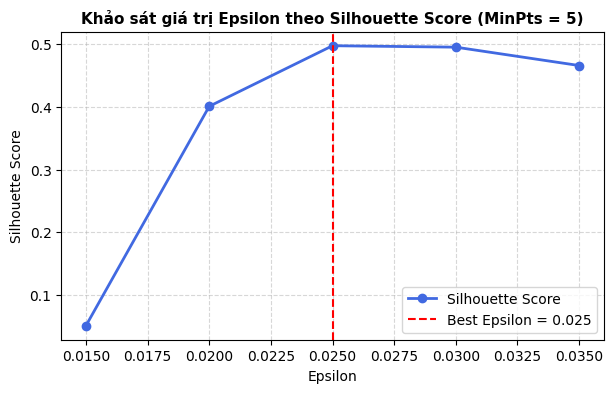

In [3]:
# 3. Canh chỉnh tham số Epsilon phù hợp với MinPts = 5 bằng Silhouette Score
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Khảo sát dải Epsilon từ 0.015 đến 0.075 với bước nhảy 0.005
eps_range = np.arange(0.015, 0.080, 0.005)
results = []

for eps in eps_range:
    db = DBSCAN(eps=eps, min_samples=5)
    labels = db.fit_predict(data_scaled[['Fresh', 'Milk']])
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    
    # Tính Silhouette Score khi có từ 2 cụm hợp lệ trở lên
    if n_clusters > 1:
        valid_idx = (labels != -1)
        score = silhouette_score(data_scaled[valid_idx], labels[valid_idx])
    else:
        score = np.nan
        
    results.append({'Epsilon': round(eps, 3), 'So_cum': n_clusters, 'So_nhieu': n_noise, 'Silhouette': round(score, 4)})

df_eval = pd.DataFrame(results)
best_eps = df_eval.loc[df_eval['Silhouette'].idxmax(), 'Epsilon']
best_score = df_eval['Silhouette'].max()

print(f"==> Epsilon tối ưu nhất: {best_eps} (Silhouette Score = {best_score:.4f})")

# Vẽ biểu đồ đường thể hiện Silhouette Score theo Epsilon
plt.figure(figsize=(7, 4))
plt.plot(df_eval['Epsilon'], df_eval['Silhouette'], marker='o', color='royalblue', linewidth=2, label='Silhouette Score')
plt.axvline(best_eps, color='red', linestyle='--', label=f'Best Epsilon = {best_eps}')
plt.title('Khảo sát giá trị Epsilon theo Silhouette Score (MinPts = 5)', fontsize=11, fontweight='bold')
plt.xlabel('Epsilon')
plt.ylabel('Silhouette Score')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
# 4. Gom cụm các đối tượng khách hàng với Epsilon tối ưu (eps = 0.025, MinPts = 5)
dbscan_model = DBSCAN(eps=best_eps, min_samples=5)
data_scaled['Cluster'] = dbscan_model.fit_predict(data_scaled[['Fresh', 'Milk']])

# Thống kê phân bố số lượng khách hàng theo từng cụm
cluster_summary = data_scaled['Cluster'].value_counts().sort_index()
print("=== PHÂN BỐ SỐ LƯỢNG KHÁCH HÀNG THEO CỤM ===")
for cl_id, count in cluster_summary.items():
    name = "Nhiễu / Outliers" if cl_id == -1 else f"Cụm {cl_id}"
    print(f"{name:18}: {count:4d} khách hàng ({count/len(data_scaled)*100:5.1f}%)")

=== PHÂN BỐ SỐ LƯỢNG KHÁCH HÀNG THEO CỤM ===
Nhiễu / Outliers  :   52 khách hàng ( 11.8%)
Cụm 0             :  378 khách hàng ( 85.9%)
Cụm 1             :    5 khách hàng (  1.1%)
Cụm 2             :    5 khách hàng (  1.1%)


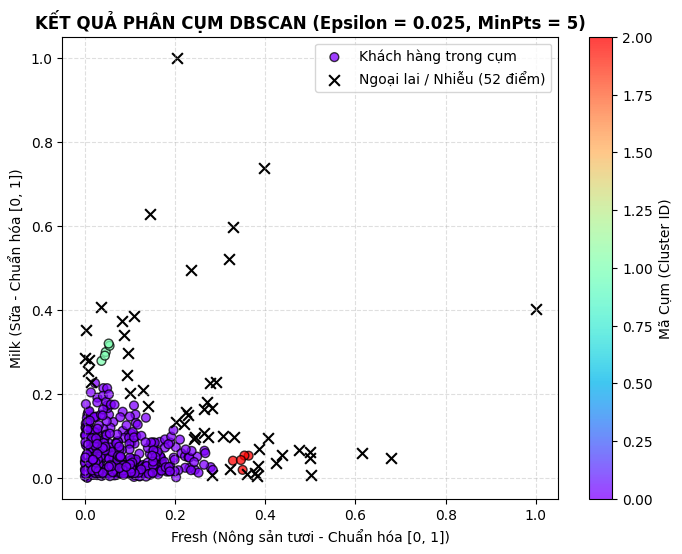

In [5]:
# 5. Vẽ biểu đồ phân tán (Scatter Plot) trực quan hóa các cụm khách hàng
plt.figure(figsize=(8, 6))

# Vẽ các điểm thuộc cụm chính (nhãn >= 0)
clustered_pts = data_scaled[data_scaled['Cluster'] != -1]
scatter = plt.scatter(
    clustered_pts['Fresh'], 
    clustered_pts['Milk'], 
    c=clustered_pts['Cluster'], 
    cmap='rainbow', 
    s=40, 
    alpha=0.75, 
    edgecolor='k',
    label='Khách hàng trong cụm'
)

# Vẽ các điểm ngoại lai / nhiễu (nhãn == -1) bằng dấu 'x' màu đen
noise_pts = data_scaled[data_scaled['Cluster'] == -1]
plt.scatter(
    noise_pts['Fresh'], 
    noise_pts['Milk'], 
    color='black', 
    marker='x', 
    s=60, 
    linewidths=1.5, 
    label=f'Ngoại lai / Nhiễu ({len(noise_pts)} điểm)'
)

plt.title(f'KẾT QUẢ PHÂN CỤM DBSCAN (Epsilon = {best_eps}, MinPts = 5)', fontsize=12, fontweight='bold')
plt.xlabel('Fresh (Nông sản tươi - Chuẩn hóa [0, 1])', fontsize=10)
plt.ylabel('Milk (Sữa - Chuẩn hóa [0, 1])', fontsize=10)
plt.colorbar(scatter, label='Mã Cụm (Cluster ID)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()